# ReLAION sharpness metrics

Compare two single-value sharpness metrics on 1000 ReLAION high-resolution samples. Every image
is center-cropped and resized to 1024x1024 before measurement.

- `sharpness`: contrast-normalized mean absolute residual after a Gaussian high-pass filter.
  Higher values mean stronger fine-scale detail, including both edges and noise.
- `cpbd`: Cumulative Probability of Blur Detection, using the Python port of the authors' MATLAB
  reference implementation. Higher values mean less perceived blur. CPBD requires grayscale
  values in the 0-255 range.

CPBD reference: https://github.com/nawta/python-cpbd-py312

Raw distributions are plotted before empirical-CDF normalization. Sorted images are hard links
to the resized PNGs, named `<position>_<normalized value>.png`.


In [1]:
import multiprocessing
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

import cpbd
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

from stdev.utils.image_tools import crop_maximal_rectangle

REPOSITORY_ROOT = Path.cwd().resolve().parent
DATASET_DIRECTORY = REPOSITORY_ROOT / "datasets" / "relaion_high_resolution_subset"
RESIZED_DIRECTORY = REPOSITORY_ROOT / "dev" / "relaion_high_resolution_subset_1024"
SHARPNESS_SORTED_DIRECTORY = REPOSITORY_ROOT / "dev" / "relaion_sorted_sharpness"
CPBD_SORTED_DIRECTORY = REPOSITORY_ROOT / "dev" / "relaion_sorted_cpbd"
METRICS_TABLE_PATH = REPOSITORY_ROOT / "dev" / "relaion_sharpness_metrics.csv"
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}
NUM_WORKERS = 8

IMAGE_SIZE = 1024
HIGH_PASS_SIGMA = 1.0
MINIMAL_CONTRAST = 0.05
METRIC_NAMES = ("sharpness", "cpbd")
SORTED_DIRECTORIES = {
    "sharpness": SHARPNESS_SORTED_DIRECTORY,
    "cpbd": CPBD_SORTED_DIRECTORY,
}


In [ ]:
def compute_simplified_sharpness(image: np.ndarray) -> float:
    """
    Measures contrast-normalized fine-scale residual strength.

    args:
        image: [H, W, 3], channel_order: BGR, pixel_values: [0...255], dtype: uint8
    returns:
        sharpness: non-negative high-frequency energy relative to global contrast
    """
    luminance = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY).astype(np.float32) / 255.0
    blurred = cv2.GaussianBlur(luminance, (0, 0), HIGH_PASS_SIGMA, borderType=cv2.BORDER_REFLECT)
    contrast = np.percentile(luminance, 95) - np.percentile(luminance, 5)
    high_frequency_energy = np.mean(np.abs(luminance - blurred))
    return float(high_frequency_energy / max(contrast, MINIMAL_CONTRAST))


def compute_cpbd(image: np.ndarray) -> float:
    """
    args:
        image: [H, W, 3], channel_order: BGR, pixel_values: [0...255], dtype: uint8
    returns:
        cpbd_value: [0...1], higher values indicate sharper images
    """
    luminance = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY).astype(np.float64)
    return float(cpbd.compute(luminance))


## Resize images and compute raw metrics


In [3]:
def process_image(image_path: Path) -> dict[str, float | str]:
    """
    Resizes one image, saves it as PNG and computes both sharpness metrics.
    """
    cv2.setNumThreads(1)
    image = cv2.imread(str(image_path))
    if image is None:
        raise ValueError(f"Could not read image: {image_path}")
    image = crop_maximal_rectangle(image, target_height=IMAGE_SIZE, target_width=IMAGE_SIZE)
    resized_path = RESIZED_DIRECTORY / f"{image_path.stem}.png"
    resized_path.parent.mkdir(parents=True, exist_ok=True)
    if not cv2.imwrite(str(resized_path), image):
        raise OSError(f"Could not write image: {resized_path}")
    return {
        "name": image_path.stem,
        "source_path": str(image_path),
        "resized_path": str(resized_path),
        "sharpness": compute_simplified_sharpness(image),
        "cpbd": compute_cpbd(image),
    }


image_paths = sorted(
    path for path in DATASET_DIRECTORY.iterdir() if path.suffix.lower() in IMAGE_EXTENSIONS
)
print(f"Found {len(image_paths)} images")
with ProcessPoolExecutor(
    max_workers=NUM_WORKERS, mp_context=multiprocessing.get_context("fork")
) as executor:
    records = list(tqdm(executor.map(process_image, image_paths), total=len(image_paths)))
metrics_table = pd.DataFrame(records)
metrics_table[list(METRIC_NAMES)].describe()


Found 1000 images


  0%|          | 0/1000 [00:00<?, ?it/s]

libpng warning: eXIf: duplicate


,sharpness,cpbd
count,1000.000000,1000.000000
mean,0.019049,0.586229
std,0.022328,0.199967
min,0.000000,0.000000
25%,0.008212,0.466938
50%,0.013777,0.608948
75%,0.023098,0.729732
max,0.388660,0.998357


## Raw distributions


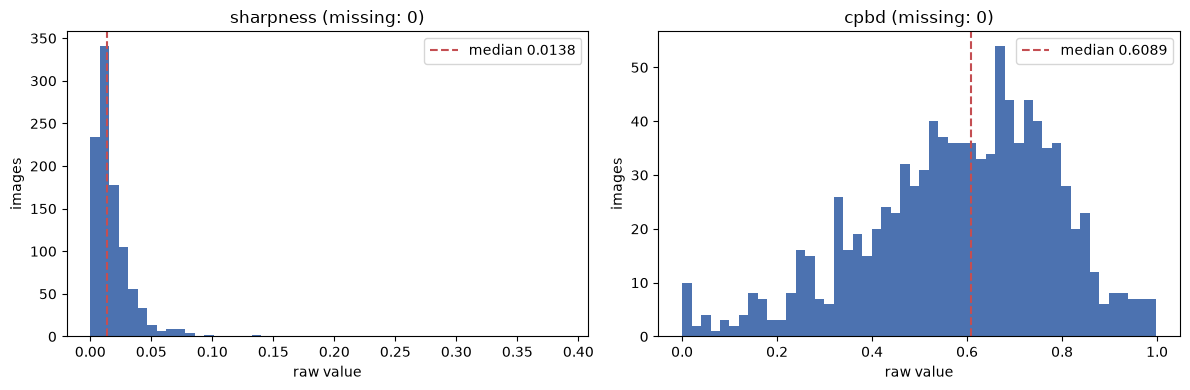

In [4]:
figure, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, metric_name in zip(axes, METRIC_NAMES):
    values = metrics_table[metric_name].dropna()
    axis.hist(values, bins=50, color="#4C72B0")
    axis.axvline(
        values.median(), color="#C44E52", linestyle="--", label=f"median {values.median():.4f}"
    )
    axis.set_title(f"{metric_name} (missing: {metrics_table[metric_name].isna().sum()})")
    axis.set_xlabel("raw value")
    axis.set_ylabel("images")
    axis.legend()
figure.tight_layout()
plt.show()


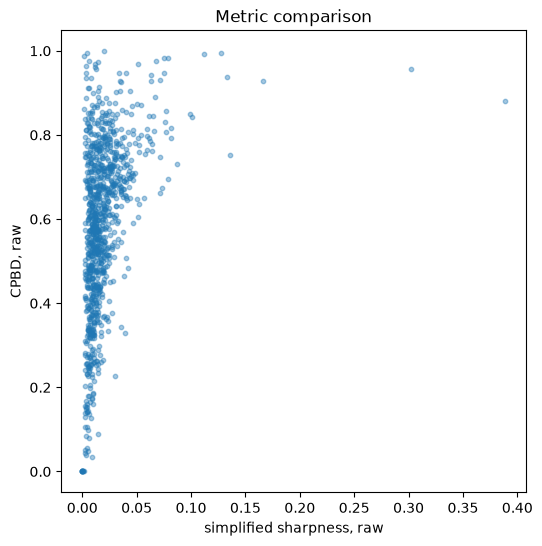

Spearman rank correlation: 0.465


In [5]:
figure, axis = plt.subplots(figsize=(6, 6))
axis.scatter(metrics_table["sharpness"], metrics_table["cpbd"], s=10, alpha=0.4)
axis.set_xlabel("simplified sharpness, raw")
axis.set_ylabel("CPBD, raw")
axis.set_title("Metric comparison")
plt.show()

spearman_correlation = metrics_table[list(METRIC_NAMES)].corr(method="spearman").iloc[0, 1]
print(f"Spearman rank correlation: {spearman_correlation:.3f}")


## Quantile normalization

Zero is the lowest dataset value and one is the highest; 0.5 is approximately the median image.


In [6]:
for metric_name in METRIC_NAMES:
    ranks = metrics_table[metric_name].rank(method="average")
    metrics_table[f"{metric_name}_normalized"] = (ranks - 1.0) / (ranks.count() - 1.0)

metrics_table.to_csv(METRICS_TABLE_PATH, index=False)
metrics_table[["name", *METRIC_NAMES, "sharpness_normalized", "cpbd_normalized"]].head()


,name,sharpness,cpbd,sharpness_normalized,cpbd_normalized
0,0000000,0.012359,0.742648,0.443443,0.768769
1,0000001,0.013238,0.576455,0.477477,0.441441
2,0000002,0.034236,0.928440,0.877878,0.973974
3,0000003,0.024198,0.507702,0.766767,0.311311
4,0000004,0.002210,0.591513,0.015015,0.467467


## Save images sorted by each metric


In [7]:
for metric_name, sorted_directory in SORTED_DIRECTORIES.items():
    sorted_directory.mkdir(parents=True, exist_ok=True)
    for old_path in sorted_directory.glob("*.png"):
        old_path.unlink()
    sorted_table = metrics_table.dropna(subset=[metric_name]).sort_values(metric_name)
    for position, row in enumerate(sorted_table.itertuples()):
        normalized_value = getattr(row, f"{metric_name}_normalized")
        target_path = sorted_directory / f"{position:04d}_{normalized_value:.4f}.png"
        target_path.hardlink_to(row.resized_path)
    print(f"{sorted_directory}: {len(sorted_table)} images")


/home/user/ML/STDev/dev/relaion_sorted_sharpness: 1000 images
/home/user/ML/STDev/dev/relaion_sorted_cpbd: 1000 images
